In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = {
    "OrderID": ["1001", "1002", "1003", "1004", "1002", "1005", "1006", "1007", "1008", "1009"],
    "Game": ["elden ring", "  Cyberpunk 2077 ", "stardew valley", "BALDUR'S GATE 3", "  Cyberpunk 2077 ", "hades", "MINECRAFT ", "the witcher 3", "terraria", "sekiro"],
    "Genre": ["soulslike", " RPG ", "simulation", "RPG", " RPG ", "roguelike", " SANDBOX ", "RPG", "sandbox", "soulslike"],
    "City": ["bengaluru", "CHENNAI ", " Bengaluru ", np.nan, "CHENNAI ", "hyderabad", "MUMBAI", " chennai ", np.nan, "bengaluru"],
    "OrderDate": ["2026-10-01", "2026/10/02", "not-a-date", "2026-10-04", "2026/10/02", "2026-10-05", "2026-10-06", "invalid-date", "2026-10-08", "2026-10-09"],
    "Quantity": ["1", "2", "3", "two", "2", "1", "4", "2", "3", "1"],
    "UnitPrice": ["59.99", "49.99", np.nan, "9999", "49.99", "24.99", "29.99", "39.99", "14.99", "69.99"],
    "Discount": ["0", "5", "10", np.nan, "5", "0", "unknown", "5", "10", "0"]
}

df = pd.DataFrame(data)
df

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount
0,1001,elden ring,soulslike,bengaluru,2026-10-01,1,59.99,0
1,1002,Cyberpunk 2077,RPG,CHENNAI,2026/10/02,2,49.99,5
2,1003,stardew valley,simulation,Bengaluru,not-a-date,3,NaN,10
3,1004,BALDUR'S GATE 3,RPG,NaN,2026-10-04,two,9999,NaN
4,1002,Cyberpunk 2077,RPG,CHENNAI,2026/10/02,2,49.99,5
5,1005,hades,roguelike,hyderabad,2026-10-05,1,24.99,0
6,1006,MINECRAFT,SANDBOX,MUMBAI,2026-10-06,4,29.99,unknown
7,1007,the witcher 3,RPG,chennai,invalid-date,2,39.99,5
8,1008,terraria,sandbox,NaN,2026-10-08,3,14.99,10
9,1009,sekiro,soulslike,bengaluru,2026-10-09,1,69.99,0


In [3]:
df.head()

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount
0,1001,elden ring,soulslike,bengaluru,2026-10-01,1,59.99,0
1,1002,Cyberpunk 2077,RPG,CHENNAI,2026/10/02,2,49.99,5
2,1003,stardew valley,simulation,Bengaluru,not-a-date,3,NaN,10
3,1004,BALDUR'S GATE 3,RPG,NaN,2026-10-04,two,9999,NaN
4,1002,Cyberpunk 2077,RPG,CHENNAI,2026/10/02,2,49.99,5


In [4]:
df.shape

(10, 8)

In [5]:
df.columns

Index(['OrderID', 'Game', 'Genre', 'City', 'OrderDate', 'Quantity',
       'UnitPrice', 'Discount'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   OrderID    10 non-null     str  
 1   Game       10 non-null     str  
 2   Genre      10 non-null     str  
 3   City       8 non-null      str  
 4   OrderDate  10 non-null     str  
 5   Quantity   10 non-null     str  
 6   UnitPrice  9 non-null      str  
 7   Discount   9 non-null      str  
dtypes: str(8)
memory usage: 772.0 bytes


In [7]:
df.describe(include="all")

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount
count,10,10,10,8,10,10,9,9
unique,9,9,7,6,9,5,8,4
top,1002,Cyberpunk 2077,soulslike,bengaluru,2026/10/02,1,49.99,0
freq,2,2,2,2,2,3,2,3


In [8]:
df.dtypes

OrderID      str
Game         str
Genre        str
City         str
OrderDate    str
Quantity     str
UnitPrice    str
Discount     str
dtype: object

In [9]:
df.isnull().sum()

OrderID      0
Game         0
Genre        0
City         2
OrderDate    0
Quantity     0
UnitPrice    1
Discount     1
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(1)

In [11]:
df.nunique()

OrderID      9
Game         9
Genre        7
City         6
OrderDate    9
Quantity     5
UnitPrice    8
Discount     4
dtype: int64

In [12]:
df["Game"] = df["Game"].str.strip().str.title()
df["Genre"] = df["Genre"].str.strip().str.lower()
df["City"] = df["City"].str.strip().str.title()
df["City"] = df["City"].fillna("Unknown")

df

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount
0,1001,Elden Ring,soulslike,Bengaluru,2026-10-01,1,59.99,0
1,1002,Cyberpunk 2077,rpg,Chennai,2026/10/02,2,49.99,5
2,1003,Stardew Valley,simulation,Bengaluru,not-a-date,3,NaN,10
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,two,9999,NaN
4,1002,Cyberpunk 2077,rpg,Chennai,2026/10/02,2,49.99,5
5,1005,Hades,roguelike,Hyderabad,2026-10-05,1,24.99,0
6,1006,Minecraft,sandbox,Mumbai,2026-10-06,4,29.99,unknown
7,1007,The Witcher 3,rpg,Chennai,invalid-date,2,39.99,5
8,1008,Terraria,sandbox,Unknown,2026-10-08,3,14.99,10
9,1009,Sekiro,soulslike,Bengaluru,2026-10-09,1,69.99,0


In [13]:
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce")

In [14]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")
df["OrderDate"]

0   2026-10-01
1          NaT
2          NaT
3   2026-10-04
4          NaT
5   2026-10-05
6   2026-10-06
7          NaT
8   2026-10-08
9   2026-10-09
Name: OrderDate, dtype: datetime64[us]

In [15]:
df["OrderDate"].isna().sum()

np.int64(4)

In [16]:
df.dtypes

OrderID                 str
Game                    str
Genre                   str
City                    str
OrderDate    datetime64[us]
Quantity            float64
UnitPrice           float64
Discount            float64
dtype: object

In [17]:
df.isnull().sum()

OrderID      0
Game         0
Genre        0
City         0
OrderDate    4
Quantity     1
UnitPrice    1
Discount     2
dtype: int64

In [18]:
df["Quantity"] = df["Quantity"].fillna(1)
df["UnitPrice"] = df["UnitPrice"].fillna(df["UnitPrice"].median())
df["Discount"] = df["Discount"].fillna(0)

In [19]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"] * (1 - df["Discount"] / 100)
df

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue
0,1001,Elden Ring,soulslike,Bengaluru,2026-10-01,1.0,59.99,0.0,59.990
1,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981
2,1003,Stardew Valley,simulation,Bengaluru,NaT,3.0,49.99,10.0,134.973
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.00,0.0,9999.000
4,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981
5,1005,Hades,roguelike,Hyderabad,2026-10-05,1.0,24.99,0.0,24.990
6,1006,Minecraft,sandbox,Mumbai,2026-10-06,4.0,29.99,0.0,119.960
7,1007,The Witcher 3,rpg,Chennai,NaT,2.0,39.99,5.0,75.981
8,1008,Terraria,sandbox,Unknown,2026-10-08,3.0,14.99,10.0,40.473
9,1009,Sekiro,soulslike,Bengaluru,2026-10-09,1.0,69.99,0.0,69.990


In [20]:
df["Month"] = df["OrderDate"].dt.to_period("M").astype("string")
df["Day"] = df["OrderDate"].dt.day
df["Weekday"] = df["OrderDate"].dt.day_name()

df

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
0,1001,Elden Ring,soulslike,Bengaluru,2026-10-01,1.0,59.99,0.0,59.990,2026-10,1.0,Thursday
1,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
2,1003,Stardew Valley,simulation,Bengaluru,NaT,3.0,49.99,10.0,134.973,<NA>,NaN,NaN
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.00,0.0,9999.000,2026-10,4.0,Sunday
4,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
5,1005,Hades,roguelike,Hyderabad,2026-10-05,1.0,24.99,0.0,24.990,2026-10,5.0,Monday
6,1006,Minecraft,sandbox,Mumbai,2026-10-06,4.0,29.99,0.0,119.960,2026-10,6.0,Tuesday
7,1007,The Witcher 3,rpg,Chennai,NaT,2.0,39.99,5.0,75.981,<NA>,NaN,NaN
8,1008,Terraria,sandbox,Unknown,2026-10-08,3.0,14.99,10.0,40.473,2026-10,8.0,Thursday
9,1009,Sekiro,soulslike,Bengaluru,2026-10-09,1.0,69.99,0.0,69.990,2026-10,9.0,Friday


In [21]:
df["Revenue"].sum()

np.float64(10715.319)

In [22]:
df["Revenue"].mean()

np.float64(1071.5319)

In [23]:
df["Revenue"].min()

np.float64(24.99)

In [24]:
df["Revenue"].max()

np.float64(9999.0)

In [25]:
df["Revenue"].count()

np.int64(10)

In [26]:
df["Quantity"].sum()

np.float64(20.0)

In [27]:
df["OrderID"].nunique()

9

In [28]:
df.agg({
    "Quantity": ["sum", "mean", "min", "max", "count"],
    "UnitPrice": ["mean", "min", "max"],
    "Revenue": ["sum", "mean", "min", "max", "count"]
})

,Quantity,UnitPrice,Revenue
sum,20.0,NaN,10715.3190
mean,2.0,1038.891,1071.5319
min,1.0,14.990,24.9900
max,4.0,9999.000,9999.0000
count,10.0,NaN,10.0000


In [29]:
region_summary = (
    df.groupby("City")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "nunique"),
        AverageRevenuePerOrder=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

region_summary

,TotalRevenue,Orders,AverageRevenuePerOrder
City,,,
Unknown,10039.473,2,5019.736500
Chennai,265.943,2,88.647667
Bengaluru,264.953,3,88.317667
Mumbai,119.960,1,119.960000
Hyderabad,24.990,1,24.990000


In [30]:
genre_summary = (
    df.groupby("Genre")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("OrderID", "nunique"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

genre_summary

,TotalRevenue,UnitsSold,Orders,AverageRevenue
Genre,,,,
rpg,10264.943,7.0,3,2566.23575
sandbox,160.433,7.0,2,80.21650
simulation,134.973,3.0,1,134.97300
soulslike,129.980,2.0,2,64.99000
roguelike,24.990,1.0,1,24.99000


In [31]:
city_summary = (
    df.groupby("City")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("OrderID", "nunique"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

city_summary

,TotalRevenue,UnitsSold,Orders,AverageRevenue
City,,,,
Unknown,10039.473,4.0,2,5019.736500
Chennai,265.943,6.0,2,88.647667
Bengaluru,264.953,5.0,3,88.317667
Mumbai,119.960,4.0,1,119.960000
Hyderabad,24.990,1.0,1,24.990000


In [32]:
game_summary = (
    df.groupby("Game")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("OrderID", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)

game_summary

,TotalRevenue,UnitsSold,Orders
Game,,,
Baldur'S Gate 3,9999.000,1.0,1
Cyberpunk 2077,189.962,4.0,1
Stardew Valley,134.973,3.0,1
Minecraft,119.960,4.0,1
The Witcher 3,75.981,2.0,1
Sekiro,69.990,1.0,1
Elden Ring,59.990,1.0,1
Terraria,40.473,3.0,1
Hades,24.990,1.0,1


In [33]:
monthly_summary = (
    df.dropna(subset=["OrderDate"])
    .assign(Month=lambda x: x["OrderDate"].dt.to_period("M"))
    .groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("OrderID", "nunique")
    )
    .sort_index()
)

monthly_summary

,TotalRevenue,UnitsSold,Orders
Month,,,
2026-10,10314.403,11.0,6


In [34]:
daily_summary = (
    df.dropna(subset=["OrderDate"])
    .groupby("OrderDate")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
    .sort_index()
)

daily_summary

,TotalRevenue,UnitsSold
OrderDate,,
2026-10-01,59.990,1.0
2026-10-04,9999.000,1.0
2026-10-05,24.990,1.0
2026-10-06,119.960,4.0
2026-10-08,40.473,3.0
2026-10-09,69.990,1.0


In [35]:
df[df["Revenue"] > df["Revenue"].mean()]

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.0,0.0,9999.0,2026-10,4.0,Sunday


In [36]:
df[df["Revenue"] == df["Revenue"].max()]

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.0,0.0,9999.0,2026-10,4.0,Sunday


In [37]:
df[df["Quantity"] >= 3]

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
2,1003,Stardew Valley,simulation,Bengaluru,NaT,3.0,49.99,10.0,134.973,<NA>,NaN,NaN
6,1006,Minecraft,sandbox,Mumbai,2026-10-06,4.0,29.99,0.0,119.960,2026-10,6.0,Tuesday
8,1008,Terraria,sandbox,Unknown,2026-10-08,3.0,14.99,10.0,40.473,2026-10,8.0,Thursday


In [38]:
df[df["Discount"] > 0]

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
1,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
2,1003,Stardew Valley,simulation,Bengaluru,NaT,3.0,49.99,10.0,134.973,<NA>,NaN,NaN
4,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
7,1007,The Witcher 3,rpg,Chennai,NaT,2.0,39.99,5.0,75.981,<NA>,NaN,NaN
8,1008,Terraria,sandbox,Unknown,2026-10-08,3.0,14.99,10.0,40.473,2026-10,8.0,Thursday


In [39]:
df[(df["Genre"] == "soulslike") & (df["Revenue"] > 50)]

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
0,1001,Elden Ring,soulslike,Bengaluru,2026-10-01,1.0,59.99,0.0,59.99,2026-10,1.0,Thursday
9,1009,Sekiro,soulslike,Bengaluru,2026-10-09,1.0,69.99,0.0,69.99,2026-10,9.0,Friday


In [40]:
df.sort_values("Revenue", ascending=False).head(5)

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.00,0.0,9999.000,2026-10,4.0,Sunday
2,1003,Stardew Valley,simulation,Bengaluru,NaT,3.0,49.99,10.0,134.973,<NA>,NaN,NaN
6,1006,Minecraft,sandbox,Mumbai,2026-10-06,4.0,29.99,0.0,119.960,2026-10,6.0,Tuesday
1,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
4,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN


In [41]:
df.sort_values("UnitPrice", ascending=False).head(5)

,OrderID,Game,Genre,City,OrderDate,Quantity,UnitPrice,Discount,Revenue,Month,Day,Weekday
3,1004,Baldur'S Gate 3,rpg,Unknown,2026-10-04,1.0,9999.00,0.0,9999.000,2026-10,4.0,Sunday
9,1009,Sekiro,soulslike,Bengaluru,2026-10-09,1.0,69.99,0.0,69.990,2026-10,9.0,Friday
0,1001,Elden Ring,soulslike,Bengaluru,2026-10-01,1.0,59.99,0.0,59.990,2026-10,1.0,Thursday
1,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN
4,1002,Cyberpunk 2077,rpg,Chennai,NaT,2.0,49.99,5.0,94.981,<NA>,NaN,NaN


In [42]:
df["SalesCategory"] = np.where(
    df["Revenue"] >= df["Revenue"].mean(),
    "High",
    "Low"
)

df[["Game", "Revenue", "SalesCategory"]]

,Game,Revenue,SalesCategory
0,Elden Ring,59.990,Low
1,Cyberpunk 2077,94.981,Low
2,Stardew Valley,134.973,Low
3,Baldur'S Gate 3,9999.000,High
4,Cyberpunk 2077,94.981,Low
5,Hades,24.990,Low
6,Minecraft,119.960,Low
7,The Witcher 3,75.981,Low
8,Terraria,40.473,Low
9,Sekiro,69.990,Low


In [43]:
df["DiscountCategory"] = np.select(
    [
        df["Discount"] == 0,
        df["Discount"] <= 5,
        df["Discount"] > 5
    ],
    [
        "No Discount",
        "Low Discount",
        "High Discount"
    ],
    default="Unknown"
)

df[["Game", "Discount", "DiscountCategory"]]

,Game,Discount,DiscountCategory
0,Elden Ring,0.0,No Discount
1,Cyberpunk 2077,5.0,Low Discount
2,Stardew Valley,10.0,High Discount
3,Baldur'S Gate 3,0.0,No Discount
4,Cyberpunk 2077,5.0,Low Discount
5,Hades,0.0,No Discount
6,Minecraft,0.0,No Discount
7,The Witcher 3,5.0,Low Discount
8,Terraria,10.0,High Discount
9,Sekiro,0.0,No Discount


In [44]:
df["PriceFlag"] = np.where(
    df["UnitPrice"] > 1000,
    "Check Price",
    "Normal"
)

df[["Game", "UnitPrice", "PriceFlag"]]

,Game,UnitPrice,PriceFlag
0,Elden Ring,59.99,Normal
1,Cyberpunk 2077,49.99,Normal
2,Stardew Valley,49.99,Normal
3,Baldur'S Gate 3,9999.00,Check Price
4,Cyberpunk 2077,49.99,Normal
5,Hades,24.99,Normal
6,Minecraft,29.99,Normal
7,The Witcher 3,39.99,Normal
8,Terraria,14.99,Normal
9,Sekiro,69.99,Normal


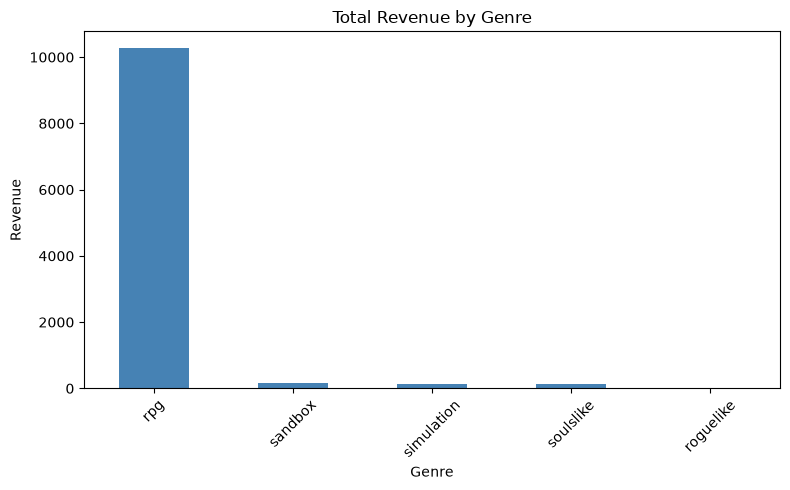

In [45]:
plt.figure(figsize=(8, 5))
genre_summary["TotalRevenue"].plot(kind="bar", color="steelblue", title="Total Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

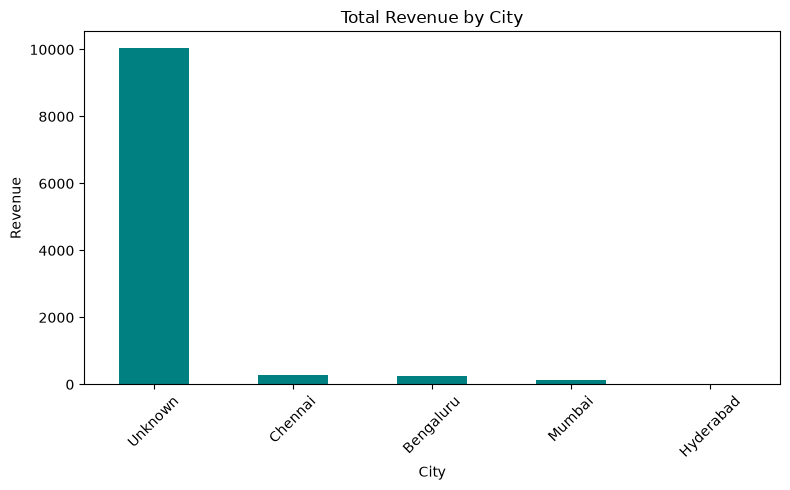

In [46]:
plt.figure(figsize=(8, 5))
city_summary["TotalRevenue"].plot(kind="bar", color="teal", title="Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

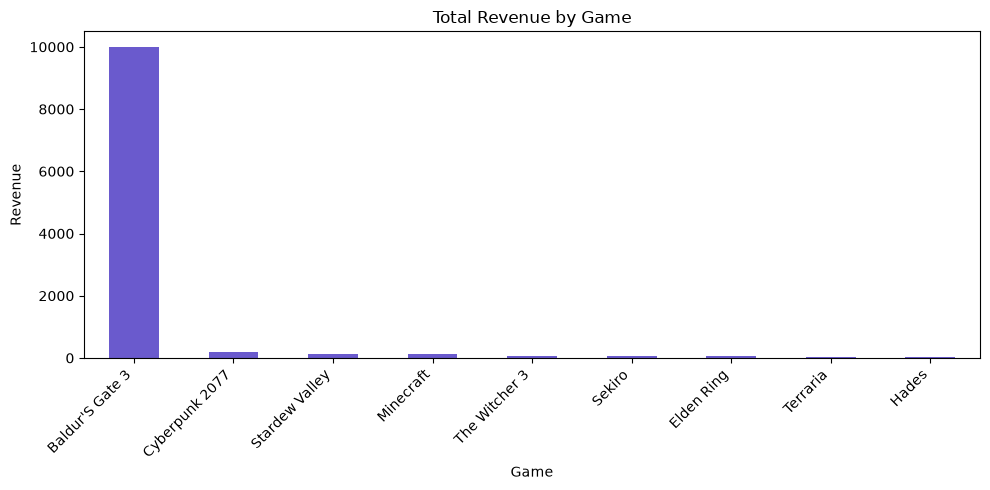

In [47]:
plt.figure(figsize=(10, 5))
game_summary["TotalRevenue"].plot(kind="bar", color="slateblue", title="Total Revenue by Game")
plt.xlabel("Game")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

/home/mithun-750/Projects/company-training/data-task/.venv/lib/python3.15/site-packages/pandas/plotting/_matplotlib/core.py:1680: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


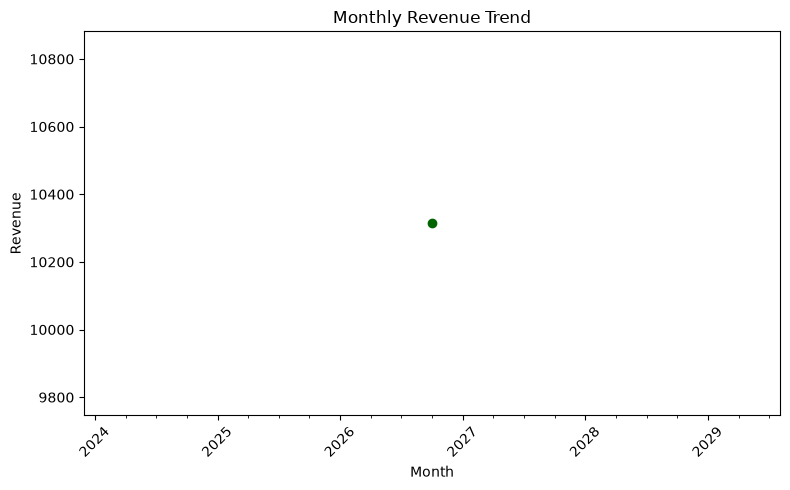

In [48]:
plt.figure(figsize=(8, 5))
monthly_summary["TotalRevenue"].plot(kind="line", marker="o", color="darkgreen", title="Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

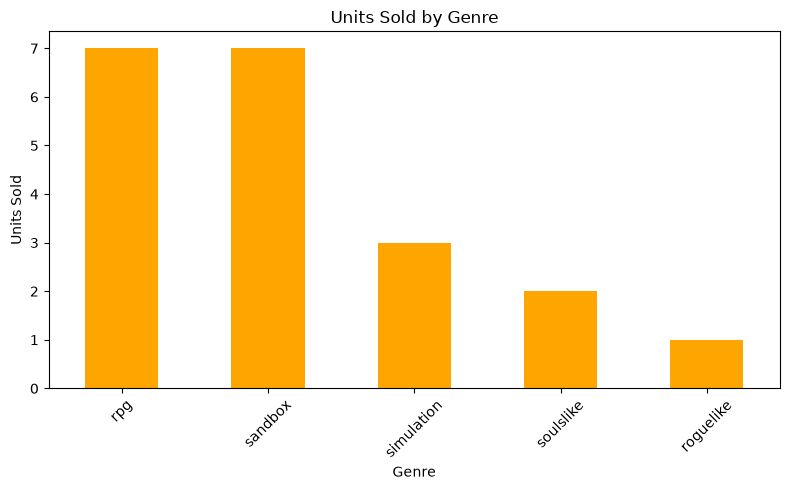

In [49]:
plt.figure(figsize=(8, 5))
genre_summary["UnitsSold"].plot(kind="bar", color="orange", title="Units Sold by Genre")
plt.xlabel("Genre")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

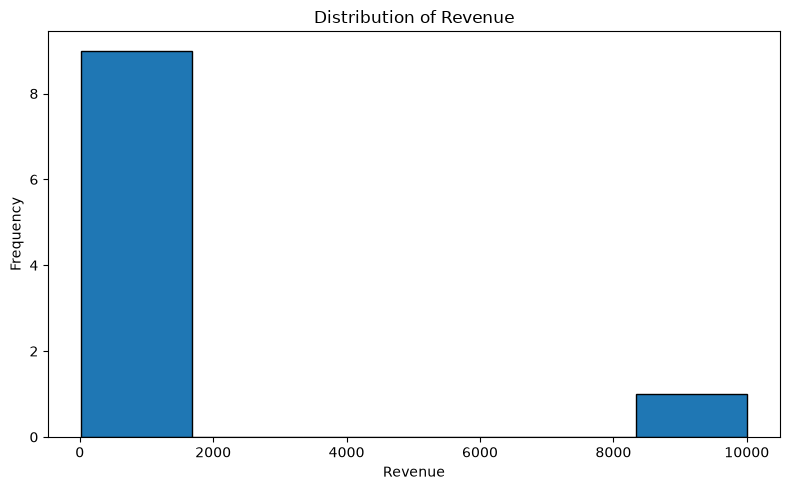

In [50]:
plt.figure(figsize=(8, 5))
plt.hist(df["Revenue"], bins=6, edgecolor="black")
plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

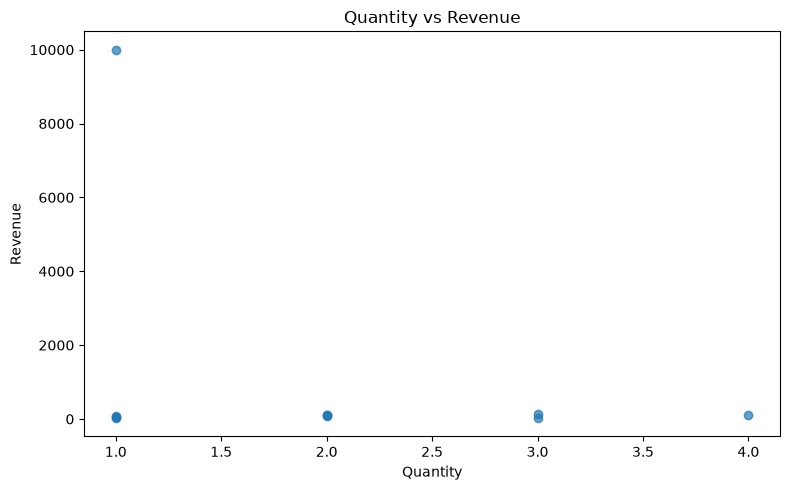

In [51]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Quantity"], df["Revenue"], alpha=0.7)
plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [52]:
print("Total Revenue:", round(df["Revenue"].sum(), 2))
print("Average Revenue:", round(df["Revenue"].mean(), 2))
print("Total Units Sold:", int(df["Quantity"].sum()))
print("Unique Orders:", df["OrderID"].nunique())
print("Unique Games:", df["Game"].nunique())
print("Highest Revenue Game:", game_summary["TotalRevenue"].idxmax())
print("Top Revenue Genre:", genre_summary["TotalRevenue"].idxmax())
print("Top Revenue City:", city_summary["TotalRevenue"].idxmax())
print("Invalid Dates:", df["OrderDate"].isna().sum())

Total Revenue: 10715.32
Average Revenue: 1071.53
Total Units Sold: 20
Unique Orders: 9
Unique Games: 9
Highest Revenue Game: Baldur'S Gate 3
Top Revenue Genre: rpg
Top Revenue City: Unknown
Invalid Dates: 4
